# Day 03 - 神经网络基础1

## 学习目标
- 掌握detach()函数的使用
- 实现pytorch模拟线性回归
- 了解pytorch中进行模型训练的工作流
- 理解神经网络的 概念 和 构成
- 理解神经元的 加权求和 和 激活函数
- 掌握常用激活函数
- 了解常见的参数初始化方法

In [1]:
# 导包
import torch
import numpy as np
import matplotlib.pyplot as plt
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题
# import matplotlib
# matplotlib.use('TKAgg')
# 设置设备
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"当前设备：{DEVICE}")

当前设备：cuda


## day03_01_自动微分_detach()函数介绍

In [2]:
"""
案例：
    演示 detach() 函数的功能，解决 开启梯度计算 requires_grad=True 的张量，无法转为numpy对象的问题
介绍：
    一个张量 一旦开启了梯度计算/自动微分 requires_grad=True，就无法转为 numpy对象，需要通过detach()函数来解决

需要掌握：
    n1 = t1.detach().numpy()

"""

# 导包
import torch
import numpy as np  # pip install numpy

# 1.定义张量，开启梯度计算
# 参数1：数据；参数2：是否开启梯度计算；参数3：数据类型
t1 = torch.tensor([1,2,3], requires_grad=True, dtype=torch.float32)
print(f"t1: {t1}, shape: {t1.shape}, dtype元素类型：{t1.dtype}")
# # 2.转为numpy数组对象, 报错
# n1 = t1.numpy()
# print(f"n1: {n1}, shape: {n1.shape}, dtype元素类型：{n1.dtype}")

# 3.演示使用detach()函数
t2 = t1.detach()
print(f"t2.requires_grad: {t2.requires_grad}")
print(f"t2: {t2}, shape: {t2.shape}, dtype元素类型：{t2.dtype}")

n1 = t2.numpy()
print(f"n1: {n1}, shape: {n1.shape}, dtype元素类型：{n1.dtype}")

# 测试 是否共享内存
n1[0] = 100
print(f"n1: {n1}, shape: {n1.shape}, dtype元素类型：{n1.dtype}")
print(f"t1: {t1}, shape: {t1.shape}, dtype元素类型：{t1.dtype}")
print(f"t2: {t2}, shape: {t2.shape}, dtype元素类型：{t2.dtype}")

t1: tensor([1., 2., 3.], requires_grad=True), shape: torch.Size([3]), dtype元素类型：torch.float32
t2.requires_grad: False
t2: tensor([1., 2., 3.]), shape: torch.Size([3]), dtype元素类型：torch.float32
n1: [1. 2. 3.], shape: (3,), dtype元素类型：float32
n1: [100.   2.   3.], shape: (3,), dtype元素类型：float32
t1: tensor([100.,   2.,   3.], requires_grad=True), shape: torch.Size([3]), dtype元素类型：torch.float32
t2: tensor([100.,   2.,   3.]), shape: torch.Size([3]), dtype元素类型：torch.float32


## day03_02_自动微分真实应用场景

- 1.前向传播，计算 预测值z
- 2.计算损失，基于loss_fn损失函数，结合 预测值z 和 真实值y, 来计算损失值loss
- 3.反向传播loss.backward()，过程中调用自动微分模块，来自动计算loss对模型参数w, b的梯度/导数
- 4.更新参数，梯度下降法，w新 = w旧 - 学习率 * 梯度
![forward_backward](assets/forward_backward.png)

In [3]:
# 0.设置随机种子
torch.manual_seed(3)
# 1.定义x， 表示：特征，输入数据
x = torch.ones(2,5)
print(f"x: {x}")

# 2.定义y, 表示：真实值
y = torch.zeros(2,1)
print(f"y: {y}")

# 3.初始化 权重w 和 偏置b, x @ w + b, (2, 1)
w = torch.randn(5,1, requires_grad=True, dtype=torch.float32)
print(f"w: {w}")
b = torch.randn(1, requires_grad=True, dtype=torch.float32)
print(f"b: {b}")

# 4.前向传播，计算 预测值z
z = x @ w + b   # (2, 1)
# z = torch.matmul(x, w) + b
print(f"z: {z}, shape: {z.shape}")

# 5.计算损失
loss_fn = torch.nn.MSELoss()
loss = loss_fn(z, y)
print(f"loss:",loss)

# 6.自动微分，执行反向传播，获取梯度：loss对w,b的梯度，注意损失函数MSELoss内部会自动求均值，不需要loss.mean()
loss.backward()

# 7.打印loss对w, b的梯度/导数
print(f"w.grad: {w.grad}")
print(f"b.grad: {b.grad}")

# 后续就是：梯度下降法来更新模型参数，w新 = w旧 - 学习率 * 梯度

x: tensor([[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]])
y: tensor([[0.],
        [0.]])
w: tensor([[ 0.8033],
        [ 0.1748],
        [ 0.0890],
        [-0.6137],
        [ 0.0462]], requires_grad=True)
b: tensor([-1.3683], requires_grad=True)
z: tensor([[-0.8687],
        [-0.8687]], grad_fn=<AddBackward0>), shape: torch.Size([2, 1])
loss: tensor(0.7547, grad_fn=<MseLossBackward0>)
w.grad: tensor([[-1.7374],
        [-1.7374],
        [-1.7374],
        [-1.7374],
        [-1.7374]])
b.grad: tensor([-1.7374])


In [4]:
# w = [w1, w2, w3, w4, w5]  = [[ 0.8033], [ 0.1748], [ 0.0890], [-0.6137], [ 0.0462]] 
# b = [b1] = [-1.3683]
# x = [[1., 1., 1., 1., 1.],
        # [1., 1., 1., 1., 1.]]
# z = x @ w + b1 = [w1 + w2 + w3 + w4 + w5 + b1, w1 + w2 + w3 + w4 + w5 + b1] = [z1, z2] = [[-0.8687], [-0.8687]]
# mse_value = (SUM(预测值 - 真实值)^2)/2 = ((z1)^2 + (z2)^2)/2 = (2*z1^2)/2 = z1^2 = (w1 + w2 + w3 + w4 + w5 + b1)^2
# mse_grad | [w1, w2, w3, w4, w5] = [2*z1*1, 2*z1*1, 2*z1*1, 2*z1*1, 2*z1*1, 2*z1*1] = [[-1.7374], [-1.7374], [-1.7374], [-1.7374], [-1.7374]]
# mse_grad | [b1] = [2*z1*1] 

## day03_03_pytorch框架_模拟线性回归
我们使用 PyTorch 的各个组件来构建线性回归模型。在pytorch中进行模型训练的工作流分为四个步骤：

- 准备数据集
- 构建模型
- 设置损失函数和优化器
- 模型训练

要使用的API：

- 使用 PyTorch 的 nn.MSELoss() 实现 平方损失函数
- 使用 PyTorch 的 data.DataLoader 实现 数据加载器
- 使用 PyTorch 的 optim.SGD 实现 优化器，执行梯度下降来更新模型参数
- 使用 PyTorch 的 nn.Linear 实现 线性回归模型

数据集x.shape:torch.Size([100, 1]), 数据集y.shape:torch.Size([100]), 数据集系数:75.95295291633313
Epoch: 0/5 | 当前轮次平均损失:5108.72791015625
Epoch: 1/5 | 当前轮次平均损失:3893.32453125
Epoch: 2/5 | 当前轮次平均损失:2879.718701171875
Epoch: 3/5 | 当前轮次平均损失:2227.995712890625
Epoch: 4/5 | 当前轮次平均损失:1726.8957958984374


C:\Users\angmi\AppData\Local\Temp\ipykernel_21396\3702676415.py:132: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


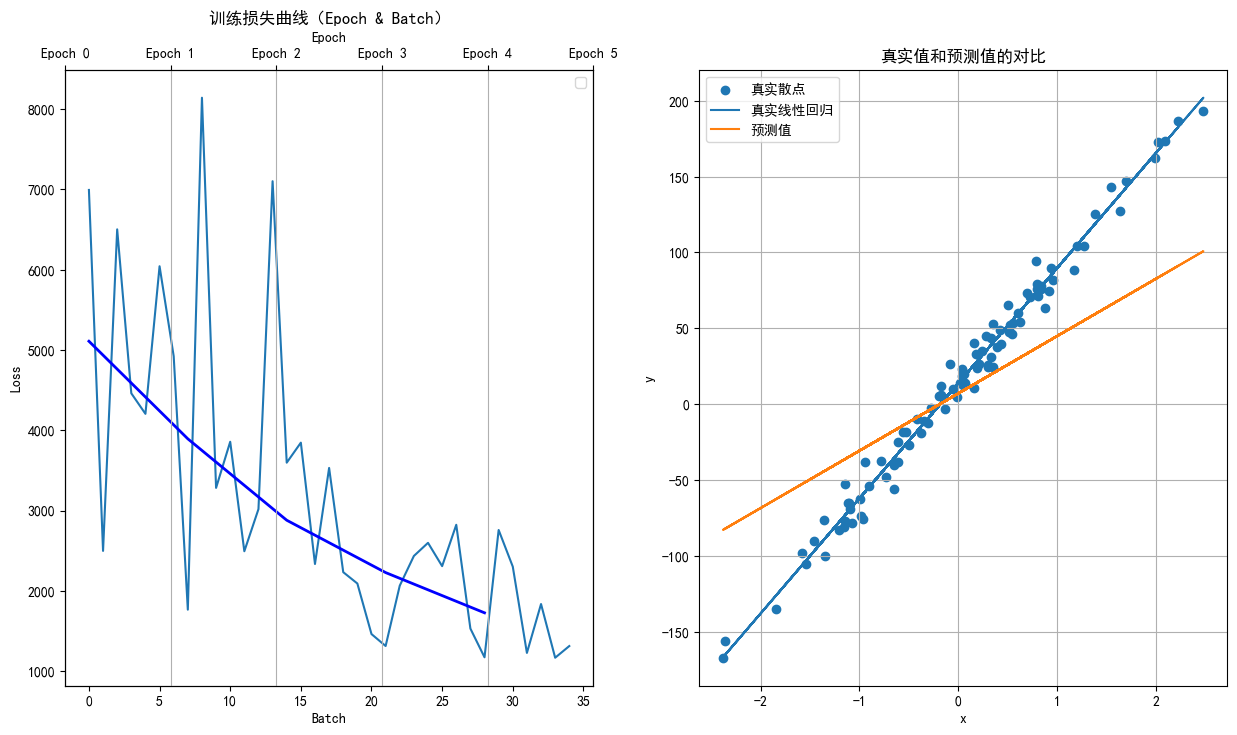

In [1]:
# 导包
import torch    # 深度学习框架pytorch
# numpy对象 -> 张量 -> 数据集对象TensorDataset -> 数据加载器DataLoader
from torch.utils.data import TensorDataset  # 构造数据集对象
from torch.utils.data import DataLoader  # 数据加载器，按批次加载数据
from torch import nn  # 神经网络模块，提供 MSE损失函数 和 线性层，线性层用来模拟线性回归模型
from torch import optim  # 提供各种优化器，用于更新模型参数，公式为：w ← w - lr * grad
from sklearn.datasets import make_regression  # 创建线性回归的示例数据集, 需要安装 pip install scikit-learn
import matplotlib.pyplot as plt # 需要安装 pip install matplotlib

# 设置matplotlib中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

# 1.准备数据集
# numpy对象 -> 张量 -> 数据集对象 -> 数据加强器(按批次加载数据，比如一个批次是64个样本)
# 定义函数，创建数据集
def create_dataset():
    # 创建数据集对象
    x, y, coef = make_regression(
        n_samples=100,          # 100条样本
        n_features=1,           # 1个特征
        n_targets=1,           # 1个标签/目标
        noise=10,           # 噪声
        bias=13.9,            # 偏移
        coef=True,          # 是否返回系数
        random_state=4          # 随机状态
    )
    # 封装成 张量
    x = torch.tensor(x, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    # 返回结果
    return x, y, coef
# 2.模型训练
def train(x,y,coef):
    # 1.准备数据集
    # 张量 -> 数据集对象 -> 数据加强器(按批次加载数据，比如一个批次是64个样本)
    # 1.1 创建数据集对象，构造输入和输出
    dataset = TensorDataset(x, y)
    # 1.2 创建数据加强器
    # 参数1：数据集对象，参数2:批次大小，
    # 参数3：是否打乱数据，训练时打乱数据，防止模型学习到无用的批次划分信息。预测/推理时，不打乱数据，因为打乱不打乱效果一样的
    # 参数4: 是否删除最后一个不完整的批次，默认False
    data_loader = DataLoader(dataset, batch_size=16, shuffle=True, drop_last=False)
    batch_per_epoch = len(data_loader)  # 每个epoch的batch数量
    # 2.构建神经网络模型
    # nn.Linear()
    model = nn.Linear(in_features=1, out_features=1)
    # 3.设置损失函数和优化器
    # nn.MSELoss, optim.SGD
    # 损失函数
    loss_fn = nn.MSELoss()
    # 优化器，执行梯度下降法，更新模型参数
    # 参数1：待训练的模型参数；参数2：学习率，10^-4~10^-2
    optimizer = optim.SGD(model.parameters(), lr=0.01)
    # 4.模型训练
    # 定义训练轮次数量
    epochs = 5
    # 记录每个轮次的平均损失，用列表记录
    loss_list = []
    # ========== 新增：记录batch损失和全局索引 ==========
    batch_losses = []          # 每个batch的损失
    global_batch_idx = 0       # 全局batch索引
    # ==================================================

    # 遍历轮数
    for epoch in range(epochs):
        # 1.初始化 当前轮次的总损失，总样本数量
        total_loss = 0.0
        total_samples = 0
        # 2.遍历批次，遍历数据加载器
        for batch_x, batch_y in data_loader:
            # 1.前向传播
            y_pred = model(batch_x)
            # 2.计算损失
            # 要求传入的张量为2D
            loss = loss_fn(y_pred, batch_y.unsqueeze(dim=1))
            # 3.梯度清零
            optimizer.zero_grad()
            # 4.反向传播
            loss.backward()
            # 5.更新参数
            optimizer.step()
            # 6.更新当前轮次的总损失 和 总样本数
            total_loss += loss.item() * batch_x.shape[0]
            total_samples += batch_x.shape[0]

            # ========== 新增：记录batch损失 ==========
            batch_losses.append(loss.item())
            global_batch_idx += 1
            # =======================================

        # 3.计算当前轮次的平均损失=当前轮次的总损失/总样本数量
        avg_loss = total_loss / total_samples
        # 4.打印当前轮次平均损失
        print(f"Epoch: {epoch}/{epochs} | "
              f"当前轮次平均损失:{avg_loss}")
        # 5.添加损失到损失列表
        loss_list.append(avg_loss)
    
    # 5.可视化训练过程
    plt.figure(figsize=(15, 8))
    # 绘制第一个子图：训练损失曲线图
    plt.subplot(1, 2, 1)
    plt.title("训练损失曲线（Epoch & Batch）")
    
    # ========== 核心修改：双坐标轴绘制 ==========
    # 1. 绘制batch损失（x轴为全局batch索引）
    x_batch = range(len(batch_losses))
    plt.plot(x_batch, batch_losses, label='Batch损失')
    
    # 2. 绘制epoch平均损失（x轴转换为batch索引：epoch * batch_per_epoch）
    x_epoch_batch = [epoch * batch_per_epoch for epoch in range(epochs)]
    plt.plot(x_epoch_batch, loss_list, color='blue', linewidth=2, label='Epoch平均损失')
    
    # 3. 设置双坐标轴
    ax1 = plt.gca()  # 获取当前坐标轴
    ax2 = ax1.twiny()  # 创建次坐标轴（顶部）
    
    # 主坐标轴（底部）：batch刻度
    ax1.set_xlabel('Batch', fontsize=10)
    ax1.set_ylabel('Loss', fontsize=10)
    
    # 次坐标轴（顶部）：epoch刻度（对应每个epoch的起始batch位置）
    epoch_ticks = range(0, epochs+1, 1)  # 每1个epoch显示一个刻度
    ax2.set_xticks([e * batch_per_epoch for e in epoch_ticks])
    ax2.set_xticklabels([f'Epoch {e}' for e in epoch_ticks])
    ax2.set_xlabel('Epoch', fontsize=10)
    # ===========================================
    
    plt.grid()
    plt.legend()
    
    # 绘制第二个子图：真实值和预测值的对比（无修改）
    plt.subplot(1, 2, 2)
    plt.title("真实值和预测值的对比")
    plt.scatter(x, y, label="真实散点")
    # 计算理论的真实线性回归直线
    y_true = [v * coef.item() + 13.9 for v in x]
    plt.plot(x, y_true, label="真实线性回归")
    # 计算模型预测值
    with torch.no_grad():  # 关闭梯度计算
        y_pred = model(x).detach().numpy()
    # 绘制模型预测的线性回归直线
    plt.plot(x, y_pred, label="预测值")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid()
    plt.legend()
    plt.show()

# 测试
if __name__ == '__main__':
    # 1.准备数据集
    x, y, coef = create_dataset()
    print(f"数据集x.shape:{x.shape}, 数据集y.shape:{y.shape}, 数据集系数:{coef}")
    # 2.模型训练
    train(x, y, coef)

coef: 56.4340604104979, shape: ()
损失列表为: [3733.35861328125, 2663.7029418945312, 1976.53541015625, 1419.078828125, 1029.4727087402343, 777.937568359375, 573.7079736328125, 429.68401977539065, 334.38183227539065, 268.46607788085936, 218.1030987548828, 185.41197875976562, 156.88349487304689, 137.52262084960938, 123.24655395507813, 113.31351531982422, 107.17456970214843, 102.98481964111328, 99.79693511962891, 97.20145446777343, 95.16941184997559, 94.06178344726563, 93.06755065917969, 92.35160705566406, 91.98932189941407, 91.70067932128906, 91.55541526794434, 91.63355728149413, 91.50667694091797, 91.4613104248047, 91.55095596313477, 91.42731750488281, 91.39078338623047, 91.35545677185058, 91.1931365966797, 91.22664123535156, 91.34032348632813, 91.29905197143555, 91.19990051269531, 91.17785095214843, 91.03748443603516, 91.14641426086426, 91.02631469726562, 91.02016418457032, 91.07926818847656, 91.17668487548828, 91.03695343017579, 91.06348999023437, 91.13747955322266, 91.09613456726075, 91.0

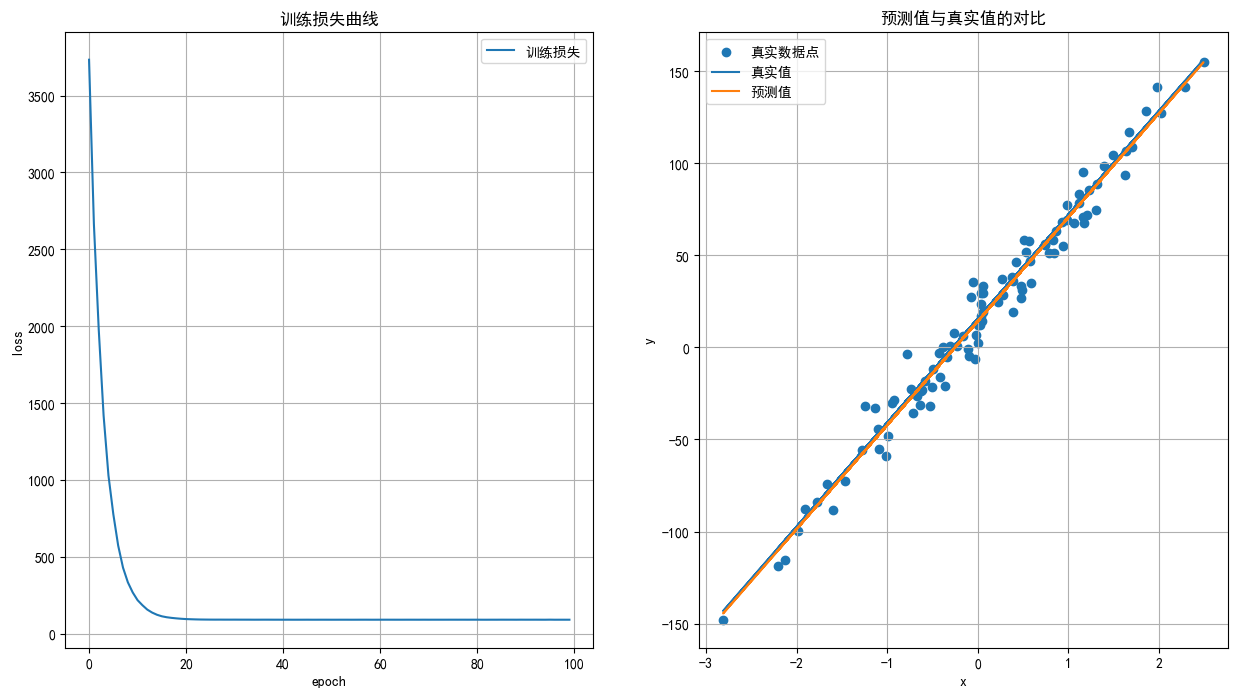

In [4]:
"""
案例：
    演示 pytorch 框架 模拟线性回归
工作流：
    1.准备数据集
    构建数据加载器：numpy对象 -> 张量 -> 数据集对象TensorDataset -> 数据加载器DataLoader
    2.构建模型
    3.设置损失函数和优化器
    4.模型训练
    5.模型测试

"""

# 导包
import torch
# numpy对象 -> 张量 -> 数据集对象TensorDataset -> 数据加载器DataLoader
from torch.utils.data import TensorDataset  # 构造数据集对象
from torch.utils.data import DataLoader  # 数据加载器，按批次加载数据
from torch import nn  # 提供 MSE损失函数 和 线性层，线性层用来模拟线性回归模型
from torch import optim  # 提供各种优化器，用于更新模型参数，公式为：w ← w - lr * grad
from sklearn.datasets import make_regression  # 创建线性回归的示例数据集, pip install scikit-learn
import matplotlib.pyplot as plt # 绘图 pip install matplotlib
# 设置matplotlib中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
# import matplotlib
# matplotlib.use('TKAgg')
# 1.准备数据集
# 定义函数，构造数据集
def create_dataset():
    # 创建数据集对象
    x, y, coef = make_regression(
        n_samples=100,  # 样本数量,100
        n_features=1,  # 特征数量,1
        n_targets=1,  # 目标数量,1
        noise=10,  # 噪声
        coef=True,  # 是否返回系数
        bias=15.6,  # 偏置
        random_state=60,
    )
    # 转换为张量
    x = torch.tensor(x, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    # 返回结果
    return x, y, coef
# 2.定义函数，实现模型训练
def train(x, y, coef):
    # 1.构建数据加载器：numpy对象 -> 张量 -> 数据集对象TensorDataset -> 数据加载器DataLoader
    dataset = TensorDataset(x, y)
    # 参数1：数据集对象；参数2：批次大小；参数3：是否打乱数据，训练时打乱，测试时不打乱；参数4：是否删除最后一个批次不满的批次
    dataloader = DataLoader(dataset, batch_size=16, shuffle=True, drop_last=False) # 100个样本，16，6*16+4
    # 2.构建模型
    model = nn.Linear(in_features=1, out_features=1)    # 自动进行参数初始化，权重w 和 偏置b
    # 3.设置损失函数和优化器
    loss_fn = nn.MSELoss()
    # 参数1：待更新的模型参数；参数2：学习率
    optimizer = optim.SGD(model.parameters(), lr=0.01)
    # 4.模型训练
    # 定义训练轮数
    epochs = 100
    # 记录 每轮的平均损失
    total_train_loss_list = []
    # 遍历轮数epochs
    for epoch in range(epochs):
        # 初始化 当前轮次的总损失值
        total_train_loss = 0.0
        # 初始化 当前轮次的样本数量
        total_samples = 0
        # 遍历数据加载器，按批次获取数据
        for train_x, train_y in dataloader:
            # 1.前向传播，计算 预测值z
            y_pred = model(train_x) # (batch_size, 1)
            # print(f"y_pred: {y_pred}, shape: {y_pred.shape}")
            # 2.计算损失
            # print(f"train_y.shape: {train_y.shape}")
            # print(f"y_pred.shape: {y_pred.shape}")
            loss = loss_fn(y_pred, train_y.reshape(-1,1))
            # print(f"loss: {loss}, shape: {loss.shape}")
            # 更新当前轮次的总损失值
            batch_size = train_x.shape[0]
            total_train_loss += loss.item() * batch_size
            total_samples += batch_size
            # 3.梯度清零
            optimizer.zero_grad()
            # 4.反向传播
            loss.backward()
            # 5.更新参数
            optimizer.step()
            
        # 计算当前轮次epoch的平均损失值
        epoch_train_loss = total_train_loss / total_samples
        total_train_loss_list.append(epoch_train_loss)
        # print(f"{epoch}轮 | "
        #       f"训练损失：{epoch_train_loss:.4f}")
        
    # 打印最终的训练损失
    print(f"损失列表为: {total_train_loss_list}")
    # 打印最终的模型参数
    print(f"模型参数为：w: {model.weight}, b: {model.bias}")
    # 直接复制
    # 6.可视化
    # 绘制损失函数曲线total_train_loss_list
    plt.figure(figsize=(15, 8))
    plt.subplot(1, 2, 1)
    plt.title("训练损失曲线")
    x_epoch = range(epochs)
    plt.plot(x_epoch, total_train_loss_list, label="训练损失")
    plt.grid()
    plt.legend()
    # 添加x轴标签
    plt.xlabel("epoch")
    # 添加y轴标签
    plt.ylabel("loss")

    # 绘制 预测值 与 真实值 的对比图
    plt.subplot(1, 2, 2)
    plt.title("预测值与真实值的对比")
    plt.scatter(x, y, label="真实数据点")
    # 计算理论的真实y值
    y_true = [v * coef.item() + 15.6 for v in x]
    plt.plot(x, y_true, label="真实值")
    # 计算预测值
    # y_pred = [v*56.4556 + 14.1016 for v in x]
    # 关闭自动微分
    with torch.no_grad():
        y_pred = model(x).detach().numpy()
    plt.plot(x, y_pred, label="预测值")
    # 添加x轴标签
    plt.xlabel("x")
    # 添加y轴标签
    plt.ylabel("y")
    # 添加图例
    plt.legend()
    # 添加网格
    plt.grid()
    plt.show()
    

# 测试
if __name__ == '__main__':
    # 1.准备数据集
    x, y, coef = create_dataset()
    # print(f"x: {x}, shape: {x.shape}")
    # print(f"y: {y}, shape: {y.shape}")
    print(f"coef: {coef}, shape: {coef.shape}")
    # plt.scatter(x, y)
    # x = torch.linspace(x.min(), x.max(), 1000)
    # y1 = torch.tensor([v * coef + 14.5 for v in x])
    # plt.plot(x, y1, label='真实数据')
    # plt.grid()
    # plt.legend()
    # plt.show()
    # 2.模型训练
    train(x, y, coef)

## 1.神经网络概念

神经网络参考了生物神经网络，数据从输入到输出经过一层一层的神经元产生预测值的过程就是**前向传播**。

前向传播涉及到人工神经元是如何工作的（也就是神经元的初始化、激活函数），神经网络如何搭建，权重参数计算、数据形状如何变化。

###  什么是神经网络

人工神经网络（Artificial Neural Network， 简写为**ANN**）也简称为神经网络（NN），是一种模仿生物神经网络结构和功能的**计算模型**。它由多个互相连接的人工神经元（也称为节点）构成，可以用于处理和学习复杂的数据模式，尤其适合解决非线性问题。人工神经网络是机器学习中的一个重要模型，在深度学习领域中得到了广泛应用。

人脑可以看做是一个生物神经网络，由众多的**神经元**连接而成。各个神经元传递复杂的电信号，树突接收到**输入信号**，然后对信号进行处理，通过轴突**输出信号**。下图是生物神经元示意图：

<img src='assets/051.png' />

当电信号通过树突进入到细胞核时，会逐渐聚集电荷。达到一定的电位后，细胞就会被激活，通过轴突发出电信号。

###  如何构建神经网络

神经网络是由多个神经元组成，构建神经网络就是在构建神经元。以下是神经网络中神经元的构建说明：

<img src='assets/081.png' />

这个流程就像，来源不同树突(树突都会有不同的权重)的信息, 进行加权计算, 输入到细胞核中，通过激活函数输出信号。

同一层的多个神经元可以看作是通过并行计算来处理相同的输入数据，学习输入数据的不同特征。每个神经元可能会关注输入数据中的不同部分，从而捕捉到数据的不同属性。

接下来，我们使用多个神经元来构建神经网络，相邻层之间的神经元相互连接，并给每一个连接分配一个强度，如下图所示：

<img src='assets/071.png' />

神经网络中信息只向一个方向移动，即从输入节点向前移动，通过隐藏节点，再向输出节点移动。其中的基本部分是:

1. **输入层/输入数据（Input Layer）**: 即输入x的那一层（如图像、文本、声音等），实际就是输入数据。输入层不是网络层，没有神经元。输入层将数据传递给下一层的神经元。

2. **输出层（Output Layer）**: 即输出y的那一层。输出层的神经元根据网络的任务（回归、分类等）生成最终的预测结果。
3. **隐藏层（Hidden Layers）**: 输入层和输出层之间都是隐藏层，神经网络的“深度”通常由隐藏层的数量决定。隐藏层的神经元通过 加权求和 和 激活函数 处理输入，并将结果传递到下一层。

- 特点是：

  - 同一网络层的神经元之间没有连接
  - 第N-1层的每个神经元和第N层的所有神经元相连（Fully Connected），全连接的网络层称为全连接层，由一个或多个全连接层组成的网络就是**全连接神经网络（FCNN）**
  - 全连接神经网络接收的输入是**2D**的，数据在每一层之间以2D的形式传递
  - 第N层网络的每个神经元的输入是 第N-1层网络的所有神经元的输出
  - 第N层网络的输入维度 = 第N-1层网络的输出维度 = 第N-1层网络的神经元数量
  - 每个连接都有一个权重值w
  - 网络层的每个神经元的模型参数有：n个权重[w1,...,wn] + 1个偏置b, n为上一网络层的输出维度

###  神经网络内部状态值和激活值

<img src="assets/image-20220313130303542.png" alt="image-20220313130303542" style="zoom:40%;" />

每一个神经元工作时，**前向传播**会产生两个值，**内部状态值（加权求和值）**和**激活值**；**反向传播**时会产生**激活值梯度**和**内部状态值梯度**。

- 内部状态值
  - 神经元或隐藏单元的内部存储值，它反映了当前神经元接收到的输入（上一层的输出）的加权求和结果。
  - 每个输入$$x_i$$都有一个与之相乘的权重$$w_i​$$，表示每个输入信号的重要性。
  - z=w⋅x+b
    - w：权重矩阵
    - x：输入值
    - b：偏置

- 激活值
  - 通过激活函数（如 ReLU、Sigmoid、Tanh）对内部状态值进行非线性变换后得到的结果。激活值决定了当前神经元的输出。
  - a=f(z)
    - f：激活函数
    - z：内部状态值

通过控制每个神经元的内部状态值和激活值的大小、每一层的内部状态值和激活值的方差可让整个神经网络工作的更好。

## 2. 激活函数

### 为什么需要激活函数？
- 引入非线性，提高模型的表达能力

### 网络非线性因素理解

- 没有引入非线性因素的网络等价于一个线性模型
- 通过给网络增加激活函数, 引入非线性因素, 使得网络模型可以逼近任意函数, 提升网络对复杂问题的拟合能力

**激活函数**用于对每层的**输出数据进行变换**, 进而为整个网络注入了**非线性因素**。此时, 神经网络就可以拟合各种曲线。如果不使用激活函数，整个网络虽然看起来复杂，其本质还相当于一种**线性模型**，如下公式所示:

<img src='assets/091.png' style="zoom:50%;"/>
<img src='assets/101.png' style="zoom:50%;"/>

另外通过图像可视化的形式理解：

<a href='http://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.97420&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false'>神经网络可视化</a>

实验表明：增加激活函数之后, 对于线性不可分的场景，神经网络的拟合能力更强。

### 常用激活函数

- 激活函数总结

| 激活函数 | 特点与描述 | 输出范围 | 常见用途 | 优点 | 缺点 |
|---------|------------|-----------|-----------|--------|--------|
| **Sigmoid** | 适用于浅层网络；容易梯度消失；输出为概率 | (0, 1) | 二分类输出层 | 输出可解释为概率 | 梯度消失；收敛慢 |
| **ReLU** | 隐藏层最常用；max(0, x)；训练快 | [0, +∞) | 各类深度网络的隐藏层 | 计算简单；不易梯度消失；稀疏性 | 负区间梯度为 0；可能 dead ReLU(实际很少见) |
| **Softmax** | 输出概率分布；总和为 1 | (0, 1)，且总和为1 | 多分类输出层 | 概率解释清晰 | 大数值不稳定（CE损失内部已处理） |
| **Tanh** | 类似 sigmoid，但零均值；仍会梯度消失 | (-1, 1) | 浅层隐藏层；归一化场景 | 比 sigmoid 更稳定 | 深层仍梯度消失 |

---

- 激活函数选择指南

| 场景 | 推荐激活函数 |
|------|--------------|
| **隐藏层** | ReLU > GELU/Leaky ReLU/PReLU > Tanh |
| **二分类（输出层）** | Sigmoid + BCELoss  **或** Softmax + CrossEntropyLoss（内部已 softmax） |
| **多分类（输出层）** | Softmax + CrossEntropyLoss（内部自动 softmax） |
| **回归任务（输出层）** | Identity（默认，无激活） |
|  - **回归值必须 ≥0** | ReLU |
|  - **回归值在 (0,1)** | Sigmoid（需对标签归一化） |
|  - **回归值在 (-1,1)** | Tanh（需标签归一化） |


### sigmoid
$$\operatorname{sigmoid}(x) = \frac{1}{1 + e^{-x}}$$
输出范围(0,1)，适用于二分类任务的输出层, 输出为正类别的概率。最大问题是容易出现梯度消失，目前使用较少

sigmoid导数：

$$\frac{d}{dx} \operatorname{sigmoid}(x) = \frac{e^{-x}}{(1 + e^{-x})^2} = \operatorname{sigmoid}(x)\left(1-\operatorname{sigmoid}(x)\right)$$


In [5]:
x=torch.tensor([-6,6], dtype=torch.float)
y=torch.sigmoid(x)
print(f"y: {y}")

y: tensor([0.0025, 0.9975])


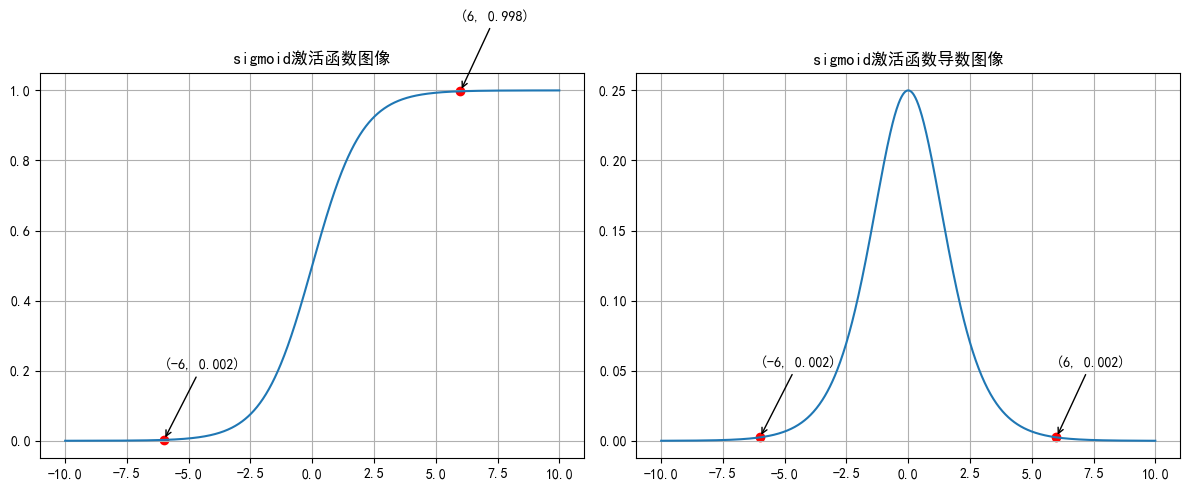

In [6]:
# 1. 创建画布和坐标轴, 1行2列.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 2. 生成 -10 ~ 10之间的 1000个数据点.
x = torch.linspace(-10, 10, 1000)

# 3. 上述1000个点, 输入sigmoid(x)
y = torch.sigmoid(x)

# 4. 在第1个子图中绘制sigmoid激活函数的图像.
axes[0].plot(x, y)
axes[0].set_title('sigmoid激活函数图像')
axes[0].grid()

# 标注点
x_points = torch.tensor([-6.0, 6.0])
y_points = torch.sigmoid(x_points)

axes[0].scatter(x_points, y_points, color='red')
for xp, yp in zip(x_points, y_points):
    axes[0].annotate(
        f"({xp.item():.0f}, {yp.item():.3f})",
        xy=(xp, yp),
        xytext=(xp, yp + 0.2),
        arrowprops=dict(arrowstyle='->')
    )

# 5. 在第2个图上, 绘制sigmoid激活函数的导数图像.
# 重新生成 -10 ~ 10之间的 1000个数据点.
# 参1: 起始值, 参2: 结束值, 参3: 元素的个数, 参4: 是否需要求导.
x = torch.linspace(-10, 10, 1000, requires_grad=True)

# 上述1000个点, 输入sigmoid进行求导，sum().backward()
torch.sigmoid(x).sum().backward()

# 绘制图像
axes[1].plot(x.detach(), x.grad)
axes[1].set_title('sigmoid激活函数导数图像')
axes[1].grid()

# 标注导数点
x_points = torch.tensor([-6.0, 6.0])
y_deriv = torch.sigmoid(x_points)*(1 - torch.sigmoid(x_points))

axes[1].scatter(x_points, y_deriv, color='red')
for xp, yp in zip(x_points, y_deriv):
    axes[1].annotate(
        f"({xp.item():.0f}, {yp.item():.3f})",
        xy=(xp, yp),
        xytext=(xp, yp + 0.05),
        arrowprops=dict(arrowstyle='->')
    )
plt.tight_layout()
plt.show()

### ReLU
$$ReLU(x) = max(0, x)$$

特点: 计算公式为max(0,x), 计算简单，收敛快，常用于隐藏层, 目前使用最多. 只考虑 正样本, 可以使用 LeakyReLU, PReLU 来考虑 负样本.

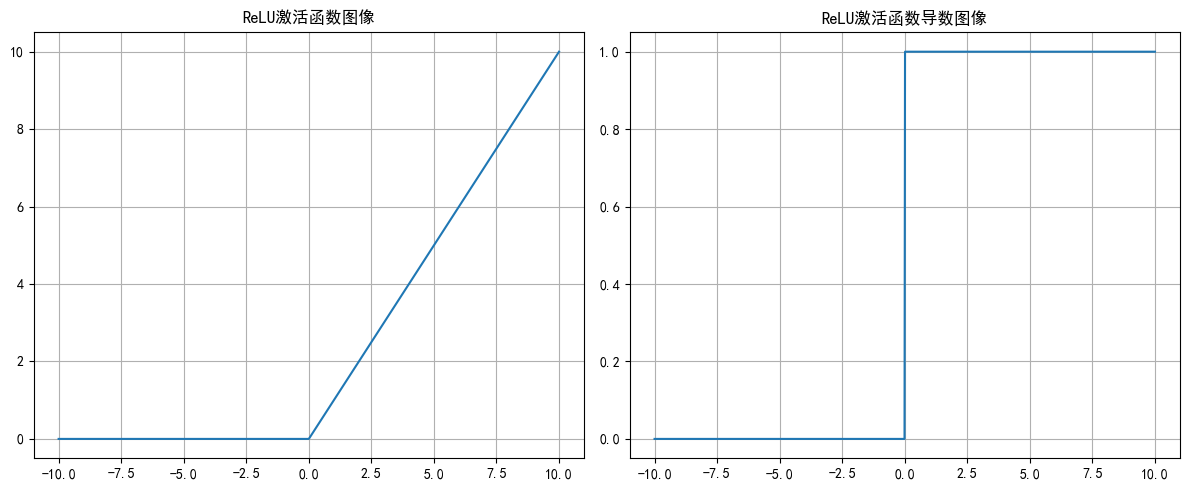

In [7]:
# 1. 创建画布和坐标轴, 1行2列.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 2. 生成 -10 ~ 10之间的 1000个数据点.
x = torch.linspace(-10, 10, 1000)

# 3. 上述1000个点, 输入ReLU(x)
y = torch.relu(x)

# 4. 在第1个子图中绘制ReLU激活函数的图像.
axes[0].plot(x, y)
axes[0].set_title('ReLU激活函数图像')
axes[0].grid()

# 5. 在第2个图上, 绘制ReLU激活函数的导数图像.
# 重新生成 -10 ~ 10之间的 1000个数据点.
# 参1: 起始值, 参2: 结束值, 参3: 元素的个数, 参4: 是否需要求导.
x = torch.linspace(-10, 10, 1000, requires_grad=True)

# 上述1000个点, 输入ReLU进行求导，sum().backward()
torch.relu(x).sum().backward()

# 绘制图像
axes[1].plot(x.detach(), x.grad)
axes[1].set_title('ReLU激活函数导数图像')
axes[1].grid()
plt.tight_layout()
plt.show()

### softmax
$$softmax(x_i) = \frac{e^{x_i}}{\sum_j e^{x_j}}$$
特点: 输出概率分布, 概率总和为1，用于多分类

softmax(x): tensor([0.0212, 0.0177, 0.0202, 0.0202, 0.0638, 0.0287, 0.0185, 0.0522, 0.0183,
        0.7392])
sum: 1.0000001192092896
softmax(softmax(x)): tensor([0.0899, 0.0896, 0.0898, 0.0898, 0.0938, 0.0906, 0.0897, 0.0927, 0.0897,
        0.1844])
sum: 1.0


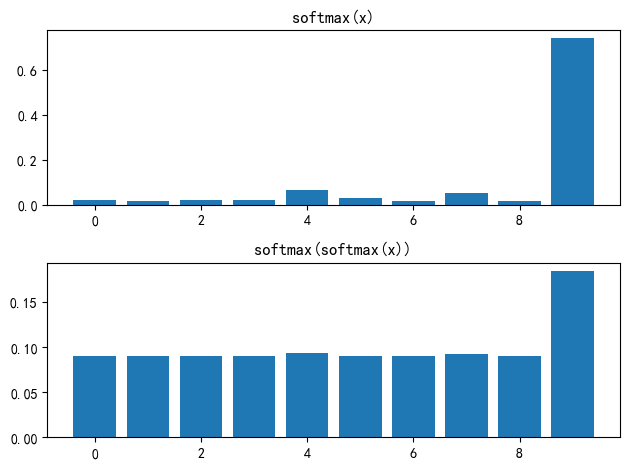

In [ ]:
# 1. 定义张量, 记录: 分类数据.
scores = torch.tensor([0.2, 0.02, 0.15, 0.15, 1.3, 0.5, 0.06, 1.1, 0.05, 3.75])
# scores = torch.tensor([[0.2, 0.35, 0.1, 0.46], [0.1, 0.13, 0.05, 2.79]])
# 2. dim = 0, 按行计算
y = torch.softmax(scores, dim=0)
print(f"softmax(x): {y}")
print(f"sum: {y.sum()}")
# 3. 再次softmax
z = torch.softmax(y, dim=0)
print(f"softmax(softmax(x)): {z}")
print(f"sum: {z.sum()}")
# 绘制柱状图
plt.subplot(2,1,1)
plt.title("softmax(x)")
plt.bar(range(len(y)), y)

plt.subplot(2,1,2)
plt.title("softmax(softmax(x))")
plt.bar(range(len(z)), z)
plt.tight_layout()
plt.show()

**二分类任务中：Sigmoid 与 Softmax 的结果是等价的**

| 二分类任务 | $$sigmoid(x)=\frac{1}{1+e^{-x}}$$ | $$\text{softmax}(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}}$$ |
|---------|-------------------|-------------------|
| 输出层网络结构 | `nn.Linear(n, 1)` | `nn.Linear(n, 2)` |
| 原始输出 logits | `[y]` | `[y0, y1]` |
| 人为设定正类 | y表示正类的logit | y1表示正类的logit,注意是人为设定的，可以修改 |
| 正类概率输出 | $$\frac{1}{1+e^{-y}}$$ | $$\frac{e^{y_1}}{e^{y_0}+e^{y_1}}=\frac{1}{1+e^{\,y_0-y_1}}$$ |
| 负类概率输出 | $$\frac{e^{-y}}{1+e^{-y}}=\frac{1}{1+e^{y}}$$ | $$\frac{e^{y_0}}{e^{y_0}+e^{y_1}}=\frac{1}{1+e^{\,y_1-y_0}}$$ |
| 转化关系 | y=y1-y0     |注意是sigmoid对应的logits= softmax对应的正类logits - 负类logits|
| 举例 | y=2,   正类概率:0.8808, 负类概率:1-0.8808=0.1192 | `[y0, y1]`=[1,3],  正类(y1)概率:0.8808, 负类(y0)概率:0.1192 |

In [40]:
import torch

logits = torch.tensor([[1, 3]], dtype=torch.float)
print(logits)

softmax = torch.softmax(logits, dim=1)
print(softmax)

logits = logits[:,1]-logits[:,0]
sigmoid = torch.sigmoid(logits)
print(sigmoid)

tensor([[1., 3.]])
tensor([[0.1192, 0.8808]])
tensor([0.8808])


### Tanh
$$tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}} = \frac{1 - e^{-2x}}{1 + e^{-2x}}$$

特点: 输出范围[-1,1]，比Sigmoid收敛快

tanh函数的导数是：

$$\frac{d}{dx} {tanh}(x) = 1 - {tanh}^2(x)$$

In [41]:
x=torch.tensor([-3,3], dtype=torch.float32)
y=torch.tanh(x)
print(f"y: {y}")

y: tensor([-0.9951,  0.9951])


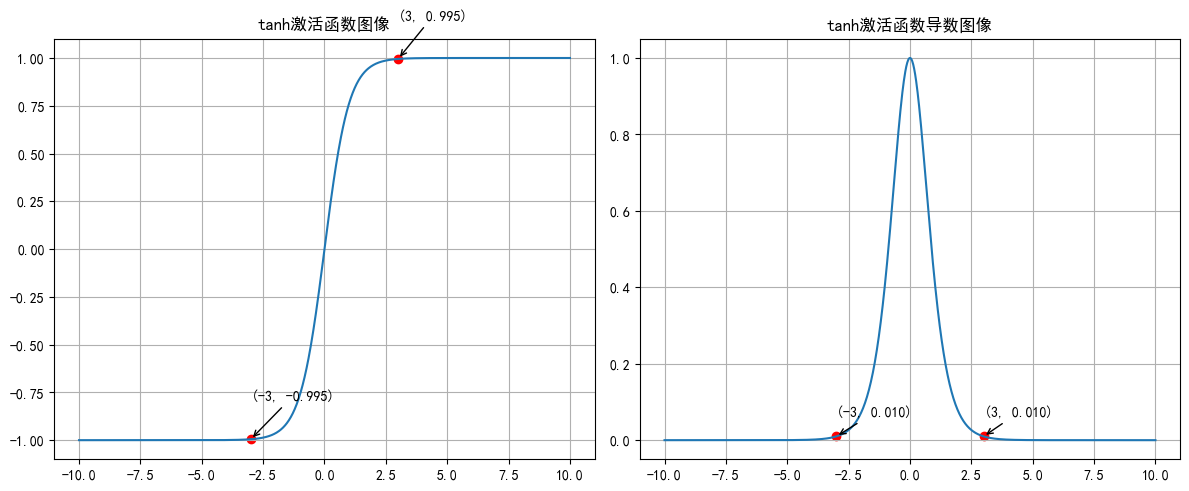

In [42]:
# 1. 创建画布和坐标轴, 1行2列.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 2. 生成 -10 ~ 10之间的 1000个数据点.
x = torch.linspace(-10, 10, 1000)

# 3. 上述1000个点, 输入tanh(x)
y = torch.tanh(x)

# 4. 在第1个子图中绘制tanh激活函数的图像.
axes[0].plot(x, y)
axes[0].set_title('tanh激活函数图像')
axes[0].grid()

# 标注点：x = -3, 3
x_points = torch.tensor([-3.0, 3.0])
y_points = torch.tanh(x_points)

axes[0].scatter(x_points, y_points, color='red')
for xp, yp in zip(x_points, y_points):
    axes[0].annotate(
        f"({xp.item():.0f}, {yp.item():.3f})",
        xy=(xp, yp),
        xytext=(xp, yp + 0.2),
        arrowprops=dict(arrowstyle='->')
    )

# 5. 在第2个图上, 绘制tanh激活函数的导数图像.
# 重新生成 -10 ~ 10之间的 1000个数据点.
# 参1: 起始值, 参2: 结束值, 参3: 元素的个数, 参4: 是否需要求导.
x = torch.linspace(-10, 10, 1000, requires_grad=True)

# 上述1000个点, 输入tanh进行求导，sum().backward()
torch.tanh(x).sum().backward()

# 绘制图像
axes[1].plot(x.detach(), x.grad)
axes[1].set_title('tanh激活函数导数图像')
axes[1].grid()

# 标注导数点：x = -3, 3
x_points = torch.tensor([-3.0, 3.0])
y_deriv = (1 - torch.tanh(x_points)**2)  # tanh' = 1 - tanh^2

axes[1].scatter(x_points, y_deriv, color='red')
for xp, yp in zip(x_points, y_deriv):
    axes[1].annotate(
        f"({xp.item():.0f}, {yp.item():.3f})",
        xy=(xp, yp),
        xytext=(xp, yp + 0.05),
        arrowprops=dict(arrowstyle='->')
    )
    
plt.tight_layout()
plt.show()

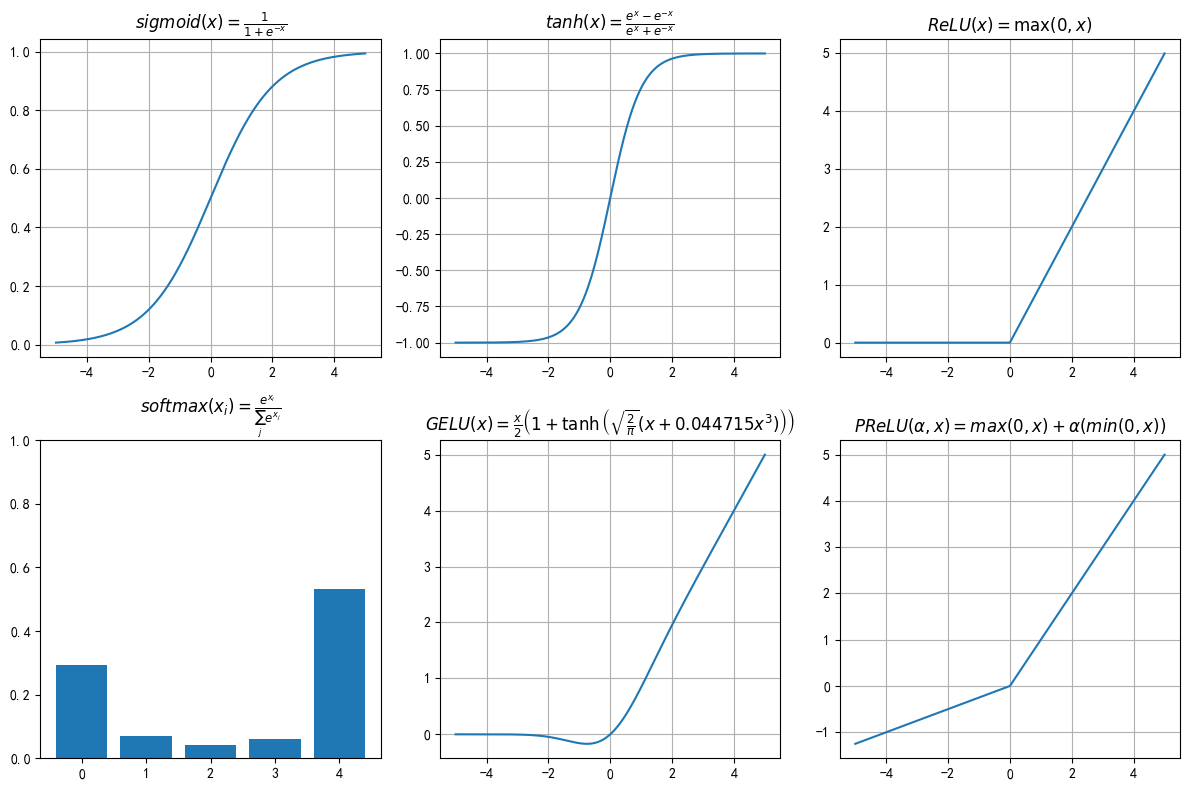

In [43]:
import torch.nn.functional as F

# 激活函数演示
x = torch.linspace(-5, 5, 1000)

# sigmoid
sigmoid = torch.sigmoid(x)

# tanh
tanh = torch.tanh(x)

# ReLU
relu = torch.relu(x)

# GELU
gelu = F.gelu(x)

# 绘制
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes[0, 0].plot(x.numpy(), sigmoid.numpy())
axes[0, 0].set_title(r'$sigmoid(x)=\frac{1}{1+e^{-x}}$')
axes[0, 0].grid(True)

axes[0, 1].plot(x.numpy(), tanh.numpy())
axes[0, 1].set_title(r'$tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}$')
axes[0, 1].grid(True)

axes[0, 2].plot(x.numpy(), relu.numpy())
axes[0, 2].set_title(r'$ReLU(x)=\max(0,x)$')
axes[0, 2].grid(True)

# softmax
softmax_input = torch.randn(5)
softmax_output = torch.softmax(softmax_input, dim=0)
axes[1, 0].bar(range(5), softmax_output.numpy())
axes[1, 0].set_title(r'$softmax(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}}$')
axes[1, 0].set_ylim([0, 1])

# GELU
axes[1, 1].plot(x.numpy(), gelu.numpy())
axes[1, 1].set_title(r'$GELU(x)=\frac{x}{2}\left(1+\tanh\left(\sqrt{\frac{2}{\pi}}\left(x+0.044715x^3\right)\right)\right)$')
axes[1, 1].grid(True)

# prelu
prelu = F.prelu(x.view(-1, 1), torch.tensor([0.25]))
axes[1, 2].plot(x.numpy(), prelu.numpy())
axes[1, 2].set_title(r'$PReLU(\alpha,x)=max(0,x)+\alpha\left(min(0,x)\right)$')
axes[1, 2].grid(True)

plt.tight_layout()
plt.show()

## 3. 参数初始化

我们在构建网络之后，网络中的参数是需要初始化的。需要初始化的参数主要有**权重**和**偏置**，**偏置一般初始化为0即可**，而对权重的初始化则会更加重要。

参数初始化的作用：

- **防止梯度消失或爆炸**：初始权重值过大或过小会导致梯度在反向传播中指数级增大或缩小。
- **提高收敛速度**：合理的初始化使得网络的激活值分布适中，有助于梯度高效更新。
- **打破对称性**：权重的初始化需要打破对称性，否则网络的学习能力会受到限制。

### 为什么要打破模型参数的对称性，防止模型参数完全相同

对称性是指：
某一层所有神经元有
- 完全相同的初始权重
- 完全相同的输入
- 完全相同的激活函数

会导致模型训练无效：
- 前向传播结果完全一样
- 反向传播时梯度完全一样
- 梯度下降更新无效 → 所有参数永远一样

- z1 = x1 * w11 + x2 * w12 + x3 * w13 + b1
- z2 = x1 * w21 + x2 * w22 + x3 * w23 + b2
- z3 = x1 * w31 + x2 * w32 + x3 * w33 + b3
- z4 = x1 * w41 + x2 * w42 + x3 * w43 + b4
- z5 = x1 * w51 + x2 * w52 + x3 * w53 + b5
- 
- w1 = w0 - lr*grad


In [44]:
# 演示 模型参数的对称性 导致了 模型训练无效

layer = nn.Linear(3, 5, bias=True)
nn.init.constant_(layer.weight, 0)
nn.init.constant_(layer.bias, 0)
# 打印模型参数
print(f"模型参数:")
print(layer.weight)
print(layer.bias)
print("-"*60)
x = torch.tensor([[1.0, 2.0, 3.0]])
# 模型前向传播
print(f"前向传播:")
print(layer(x))
print("-"*60)

y = layer(x)
loss = y.sum()      # 简单损失
loss.backward()
# 获取梯度
print(f"梯度:")
print(layer.weight.grad)
print(layer.bias.grad)
print("-"*60)
# 模型参数更新
layer.weight.data -= 0.01 * layer.weight.grad
layer.bias.data -= 0.01 * layer.bias.grad
print(f"更新后的模型参数:")
print(layer.weight)
print(layer.bias)
print("-"*60)

# 结论
print("结论:")
print("模型参数的对称性 导致 梯度完全相同，更新后的模型参数完全相同，模型训练无效")

模型参数:
Parameter containing:
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]], requires_grad=True)
Parameter containing:
tensor([0., 0., 0., 0., 0.], requires_grad=True)
------------------------------------------------------------
前向传播:
tensor([[0., 0., 0., 0., 0.]], grad_fn=<AddmmBackward0>)
------------------------------------------------------------
梯度:
tensor([[1., 2., 3.],
        [1., 2., 3.],
        [1., 2., 3.],
        [1., 2., 3.],
        [1., 2., 3.]])
tensor([1., 1., 1., 1., 1.])
------------------------------------------------------------
更新后的模型参数:
Parameter containing:
tensor([[-0.0100, -0.0200, -0.0300],
        [-0.0100, -0.0200, -0.0300],
        [-0.0100, -0.0200, -0.0300],
        [-0.0100, -0.0200, -0.0300],
        [-0.0100, -0.0200, -0.0300]], requires_grad=True)
Parameter containing:
tensor([-0.0100, -0.0100, -0.0100, -0.0100, -0.0100], requires_grad=True)
----------------------------------------------

###  常见参数初始化方法

- **均匀分布初始化**：权重参数初始化从区间均匀随机取值，默认区间为（0，1）。可以设置为在 $$U(\frac{-1}{\sqrt{d}}, \frac{1}{\sqrt{d}})$$ 均匀分布中生成当前神经元的权重，其中d为神经元的输入维度。
  - **优点**：能有效打破对称性

  - **缺点**：随机选择范围不当可能导致梯度问题

  - **适用场景**：浅层网络或低复杂度模型。隐藏层1-3层，总层数不超过5层。

In [45]:
print("1. 均匀分布初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 对权重w 进行初始化
nn.init.uniform_(linear.weight)
# 对偏置b 进行初始化
nn.init.uniform_(linear.bias)
# 打印
print(linear.weight.data)
print(linear.bias.data)
print("-"*60)

1. 均匀分布初始化
tensor([[0.9185, 0.2671, 0.4771],
        [0.7458, 0.2072, 0.1443],
        [0.7757, 0.8209, 0.9910],
        [0.1623, 0.3620, 0.3269],
        [0.3248, 0.0230, 0.7356]])
tensor([0.3758, 0.0809, 0.4650, 0.7812, 0.8545])
------------------------------------------------------------


- **正态分布初始化**：随机初始化从均值为0，标准差是1的高斯分布 $$N(0,1)$$中取样，使用一些很小的值对参数W进行初始化

  - **优点**：能有效打破对称性

  - **缺点**：随机选择范围不当可能导致梯度问题

  - **适用场景**：浅层网络或低复杂度模型。隐藏层1-3层，总层数不超过5层。

In [46]:
print("2. 正态分布初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 对权重w 进行初始化
nn.init.normal_(linear.weight)
# 对偏置b 进行初始化
nn.init.normal_(linear.bias)
# 打印
print(linear.weight.data)
print(linear.bias.data)
print("-"*60)

2. 正态分布初始化
tensor([[-0.0244,  0.2668, -1.2721],
        [ 1.0663, -0.3558,  0.2848],
        [-0.4158,  1.5660, -1.1663],
        [-0.1668, -1.1263,  0.2289],
        [-0.2518, -0.2090,  1.3870]])
tensor([-0.4617,  1.7896, -1.9366, -1.6447,  2.6452])
------------------------------------------------------------


- **全0初始化**：将神经网络中的所有权重参数初始化为0
  - **优点**：实现简单
  - **缺点**：无法打破对称性，所有神经元更新方向相同，无法有效训练
  - **适用场景**：几乎不使用，仅用于偏置项的初始化

In [47]:
print("3. 全0初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 对权重w 进行初始化
nn.init.zeros_(linear.weight)
# 对偏置b 进行初始化
nn.init.zeros_(linear.bias)
# 打印
print(linear.weight.data)
print(linear.bias.data)
print("-"*60)

3. 全0初始化
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
tensor([0., 0., 0., 0., 0.])
------------------------------------------------------------


- **全1初始化**：将神经网络中的所有权重参数初始化为1
  - **优点**：实现简单
  - **缺点**
    - 无法打破对称性，所有神经元更新方向相同，无法有效训练
    - 会导致激活值在网络中呈指数增长，容易出现梯度爆炸
  - **适用场景**
    - 测试或调试：比如验证神经网络是否能正常前向传播和反向传播
    - 特殊模型结构：某些稀疏网络或特定的自定义网络中可能需要手动设置部分参数为1

In [48]:
print("4. 全1初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 对权重w 进行初始化
nn.init.ones_(linear.weight)
# 对偏置b 进行初始化
nn.init.ones_(linear.bias)
# 打印
print(linear.weight.data)
print(linear.bias.data)
print("-"*60)

4. 全1初始化
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
tensor([1., 1., 1., 1., 1.])
------------------------------------------------------------


- **固定值初始化**：将神经网络中的所有权重参数初始化为某个固定值
  - **优点**：实现简单
  - **缺点**
    - 无法打破对称性，所有神经元更新方向相同，无法有效训练
    - 初始权重过大或过小可能导致梯度爆炸或梯度消失
  - **适用场景**
    - 测试或调试
    - 偏置初始化：偶尔可以将偏置初始化为小的正值（如 0.1）

In [49]:
print("5. 固定值初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 对权重w 进行初始化
nn.init.constant_(linear.weight, 6)
# 对偏置b 进行初始化
nn.init.constant_(linear.bias, 6)
# 打印
print(linear.weight.data)
print(linear.bias.data)
print("-"*60)

5. 固定值初始化
tensor([[6., 6., 6.],
        [6., 6., 6.],
        [6., 6., 6.],
        [6., 6., 6.],
        [6., 6., 6.]])
tensor([6., 6., 6., 6., 6.])
------------------------------------------------------------


- **kaiming初始化(针对ReLU)**，也叫做**HE初始化**：专为ReLU和其变体设计，考虑到ReLU激活函数的特性，对输入维度进行缩放
  - HE初始化分为正态分布的HE初始化、均匀分布的HE初始化
    - 正态分布的he初始化
      - w权重值
      $$W \sim N(0, \sqrt{\frac{2} {fan\_in}})$$
      - std值较大，w权重值离均值0分布相对较广，计算得到的内部状态值有较大的正值或负值
    - 均匀分布的he初始化
      - w权重值
      $$W \sim U(-\sqrt{\frac{6} {fan\_in}}, \sqrt{\frac{6} {fan\_in}})$$
    - `fan_in` 当前层的输入维度，即**当前层**接受的**来自上一层**的神经元的数量。简单来说，就是当前层接收多少个输入
  - **优点**：适合 ReLU，能保持梯度稳定
  - **缺点**：对非 ReLU 激活函数效果一般
  - **适用场景**：深度网络(10层及以上)，使用 ReLU、Leaky ReLU 激活函数

In [50]:
print("6. kaiming 初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 正态分布的he初始化
print("正态分布的he初始化")
# 对权重w 进行初始化
nn.init.kaiming_normal_(linear.weight)
# 打印
print(linear.weight.data)
# 均匀分布的he初始化
print("均匀分布的he初始化")
# 对权重w 进行初始化
nn.init.kaiming_uniform_(linear.weight)
# 打印
print(linear.weight.data)
print("-"*60)

6. kaiming 初始化
正态分布的he初始化
tensor([[ 1.3120,  1.3367,  0.4253],
        [ 0.7838,  0.7619, -0.8062],
        [-0.3193,  0.6067,  0.0941],
        [-0.2564,  0.0382,  0.3053],
        [ 0.4095,  1.4643,  1.2610]])
均匀分布的he初始化
tensor([[ 1.3505, -1.2915, -0.1702],
        [-0.8592, -0.2620, -1.3055],
        [ 0.8883,  1.0915, -1.3323],
        [ 0.5415, -1.1120,  0.5657],
        [-0.7347,  0.7756, -0.4481]])
------------------------------------------------------------


- **xavier初始化(针对Sigmoid、Tanh)**，也叫做**Glorot初始化**：根据网络输入和输出的维度自动选择权重范围，使输入和输出的方差相同
  - xavier初始化分为正态分布的xavier初始化、均匀分布的xavier初始化
    - 正态分布的Xavier初始化
      - w权重值
      $$W \sim N(0, \sqrt{\frac{2} {fan\_in + fan\_out}})$$
      - std值较小，w权重值离均值0分布相对集中，计算得到的内部状态值有较小的正值或负值
    - 均匀分布的Xavier初始化
      - w权重值
      $$W \sim U(-\sqrt{\frac{6} {fan\_in + fan\_out}}, \sqrt{\frac{6} {fan\_in + fan\_out}})$$
    - `fan_in` 当前层的输入维度，**当前层**接受的**来自上一层**的神经元的数量。简单来说，就是当前层接收多少个输入
    - `fan_out` 当前层的输出维度，**当前层**输出的神经元的数量，也就是当前层会传递给**下一层**的神经元的数量。简单来说，就是当前层会产生多少个输出。

  - **优点**：适用于Sigmoid、Tanh 等激活函数，解决梯度消失问题
  - **缺点**：对 ReLU 等激活函数表现欠佳
  - **适用场景**：深度网络(10层及以上)，使用 Sigmoid 或 Tanh 激活函数

In [51]:
print("7.xavier 初始化")
# 创建一个线性层，输入维度3，输出维度5
linear = nn.Linear(3, 5)
# 正态分布的xavier初始化
print("正态分布的xavier初始化")
# 对权重w 进行初始化
nn.init.xavier_normal_(linear.weight)
# 打印
print(linear.weight.data)
# 均匀分布的xavier初始化
print("均匀分布的xavier初始化")
# 对权重w 进行初始化
nn.init.xavier_uniform_(linear.weight)
# 打印
print(linear.weight.data)
print("-"*60)

7.xavier 初始化
正态分布的xavier初始化
tensor([[-0.8691,  0.2169,  0.2708],
        [-0.1967, -0.2776, -0.2853],
        [ 0.2053,  0.0710,  0.0017],
        [ 0.0023,  1.1975, -0.7303],
        [ 0.6664,  0.1996,  0.6238]])
均匀分布的xavier初始化
tensor([[ 0.2249, -0.8194, -0.6806],
        [ 0.2372,  0.5229, -0.4022],
        [ 0.5650,  0.2191,  0.7264],
        [ 0.3289, -0.1162, -0.5671],
        [ 0.1529, -0.5503, -0.4963]])
------------------------------------------------------------


## 常见面试题

### 1. 简述人工神经网络的计算模型

**人工神经网络 具有多层网络结构，每层网络包含多个神经元，每个神经元都有权重和偏置，能够执行 加权求和+激活函数**的运算：
- 加权求和：$z = w \cdot x + b$（$w$权重，$x$输入，$b$偏置）
- 激活值：$a = f(z)$（$f$是激活函数）
- **前向传播**：数据从输入层→隐藏层→输出层逐层计算
- **特点**：层与层间全连接，同层神经元无连接

---

### 2. 激活函数的作用是什么，常用的激活函数有哪些？
- 引入非线性，使网络具有非线性表达能力
- 常用的激活函数有ReLU, LeakyReLU, softmax, sigmoid等

---

### 3. 为什么sigmoid激活函数有梯度消失问题，如何解决？

- **原因**：Sigmoid导数为 $sigmoid'(x) = sigmoid(x)(1-sigmoid(x))$，最大值仅为0.25。深层网络反向传播时，梯度连乘会指数衰减 为十分接近0（如$0.25^{10} \approx 0$），导致深层参数无法更新
- **解决方案**：
  - 使用**ReLU激活函数**（导数为0或1，梯度不衰减）
  - **Batch Normalization归一化**（标准化输入分布）
  - **残差连接**（Skip Connection，绕过深层）
  - 采用更好的**初始化方法**（Xavier、Kaiming）

---

### 4. ReLU激活函数的公式是什么，有哪些特点？
  - 公式 $max(0,x)$
  - 特点：
    - 简单快速
    - 梯度不衰减
    - 隐藏层首选
    - 存在Dead ReLU问题，但实际情况十分少见


### 5. 如何选择激活函数？
**隐藏层激活函数**：
1. **ReLU**
   - 最快最简单，大多数场景够用
   - 可能出现Dead ReLU，实际很少发生
   - 用法：`torch.nn.ReLU()`

2. **LeakyReLU**（当ReLU不理想时）
   - 完全解决Dead ReLU问题
   - 速度与ReLU接近
   - 用法：`torch.nn.LeakyReLU(negative_slope=0.01)`

3. **GELU**（Transformer时代推荐）
   - 平滑可微，性能优秀
   - 计算量是ReLU的3-4倍
   - 用法：`torch.nn.GELU()` 或 `torch.nn.GELU(approximate='tanh')`

 **输出层激活函数**：
- **多分类**：`Linear + CrossEntropyLoss(内部使用Softmax)`
- **二分类**：`Linear + CrossEntropyLoss(内部使用Softmax)` 或 `Sigmoid + BCELoss`
- **回归**：无激活函数（线性输出）

### 6. 说一下kaiming初始化的原理和应用场景

**kaiming初始化有两种方式：正太分布 和 均匀分布**
- 正态分布的kaiming初始化为
      $$模型权重W \sim N(0, \sqrt{\frac{2} {fan\_in}})$$
    - `fan_in` 当前层的输入维度
- 均匀分布的kaiming初始化为
      $$模型权重W \sim U(-\sqrt{\frac{6} {fan\_in}}, \sqrt{\frac{6} {fan\_in}})$$
    - `fan_in` 当前层的输入维度

**应用场景**：
适用于 使用ReLU的深度网络的模型权重的参数初始化，能够保持梯度稳定

---

## 代码作业

- 1.使用torch.randn创建形状为(3,4)的随机张量，开启梯度计算，使用detach()方法将张量转换为NumPy数组, 并打印。
- 2.修改pytorch模拟线性回归中的参数或设置，比如n_samples改为200，batch_size改为32，epochs改为200，学习率改为0.001，loss_fn改为MAE，并绘制训练过程中损失值的变化曲线。
- 3.使用代码演示 二分类任务中，softmax和sigmoid函数的等价关系，比如原始输出的logits为：两个类别[1,3]，单个类别为[2],分别使用softmax和sigmoid计算正类别和负类别的概率，并打印。
- 4.创建一个线性层，输入维度3，输出维度5，权重初始化采用kaiming正态分布，偏置初始化采用全0初始化，并打印初始化的权重和偏置。

## 扩展-推荐学习资料
- 动手学机器学习
https://hml.boyuai.com/

- 动手学深度学习
https://zh-v2.d2l.ai/

- 动手学强化学习
https://hrl.boyuai.com/

## 扩展-GELU激活函数（Gaussian Error Linear Unit）


### 定义公式

GELU 的常用近似形式（Transformer 默认版本）为：

$$
\text{GELU}(x)
= 0.5x\left(1 + \tanh\left(\sqrt{\frac{2}{\pi}}(x + 0.044715x^3)\right)\right)
$$

其精确形式为：

$$
\text{GELU}(x) = x \cdot \Phi(x)
$$

其中 $\Phi(x)$ 是标准正态分布的 CDF。

---

### 2. 特点

* **平滑非线性**：相比 ReLU 的硬截断，GELU 更平滑，有助于梯度稳定。
* **概率式门控**：输出大小取决于输入落在正态分布右侧的概率，具有一定“自适应性”。
* **轻微保留负值**：不像 ReLU 将负值全部置零，有助于表示能力提升。
* **性能优势明显**：在 NLP 模型中普遍优于 ReLU、Swish 等传统激活函数。

---

### 3. 应用场景

* **Transformer / BERT / GPT 系列默认激活函数**
* Vision Transformer (ViT)
* 大多数现代 NLP、CV 大模型中广泛应用
* 已逐渐成为“默认的高性能激活函数”



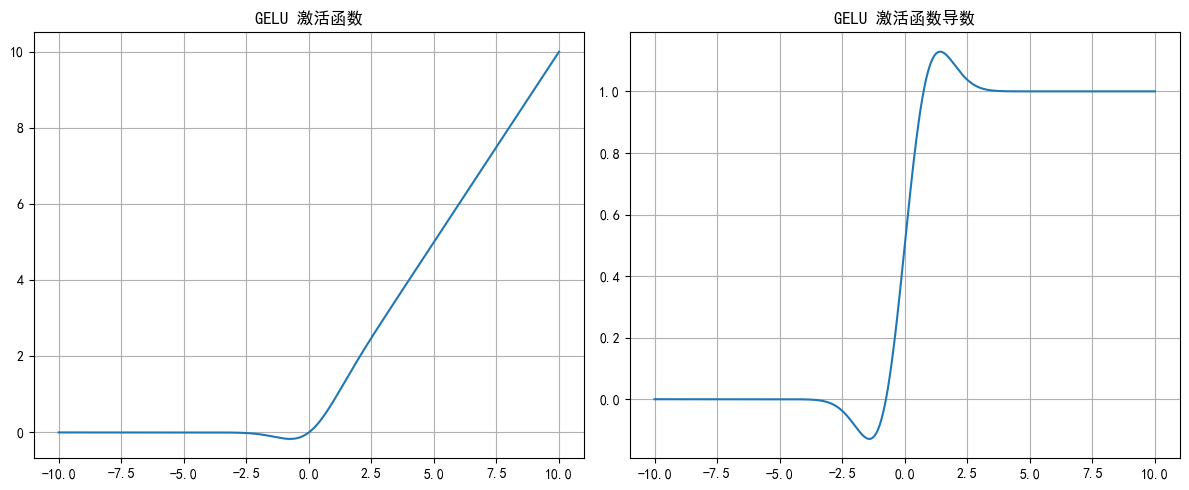

In [32]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. 创建画布和坐标轴（1行2列）
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# =====================
#   GELU 激活函数曲线
# =====================

# 2. 生成 -10 到 10 的 1000 个数据点
x = torch.linspace(-10, 10, 1000)

# 3. GELU(x)
y = F.gelu(x)

# 4. 绘制 GELU 激活函数
axes[0].plot(x, y)
axes[0].set_title('GELU 激活函数')
axes[0].grid()

# =====================
#   GELU 激活函数导数
# =====================

# 5. 重新生成可求导的数据
x = torch.linspace(-10, 10, 1000, requires_grad=True)

# 6. GELU(x) 求导
F.gelu(x).sum().backward()

# 7. 绘制导函数曲线
axes[1].plot(x.detach(), x.grad)
axes[1].set_title('GELU 激活函数导数')
axes[1].grid()

plt.tight_layout()
plt.show()

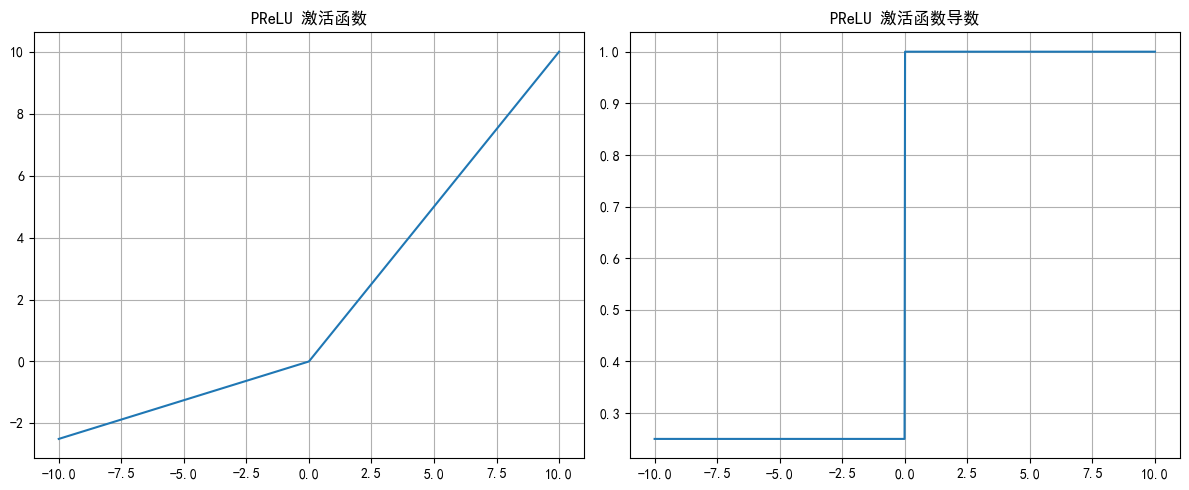

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. 创建画布和坐标轴（1行2列）
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# =====================
#   GELU 激活函数曲线
# =====================

# 2. 生成 -10 到 10 的 1000 个数据点
x = torch.linspace(-10, 10, 1000)

# 3. PReLU(x)
y = F.prelu(x, torch.tensor([0.25]))

# 4. 绘制 PReLU 激活函数
axes[0].plot(x, y)
axes[0].set_title('PReLU 激活函数')
axes[0].grid()

# =====================
#   PReLU 激活函数导数
# =====================

# 5. 重新生成可求导的数据
x = torch.linspace(-10, 10, 1000, requires_grad=True)

# 6. PReLU(x) 求导
F.prelu(x, torch.tensor([0.25])).sum().backward()

# 7. 绘制导函数曲线
axes[1].plot(x.detach(), x.grad)
axes[1].set_title('PReLU 激活函数导数')
axes[1].grid()

plt.tight_layout()
plt.show()